# 3. Scale

> **Overview.** An agent may pose thousands of predictions, learned by a sparse network of millions of LTUs. Prior
> success uses only the statistics of each output and of each LTU. Does it keep its gain as the network and the number
> of outputs grow together?

**Setup.** Notebook 2's learner, with parents drawn uniformly (baseline) or by prior success (proposed). The problem
has 1, 2, 4 or 8 copies of notebook 1's problem with noisy linear decoys, side by side on the
same 400 inputs: 20 to 160 outputs. The learner has 32 LTUs per copy, and search replaces 4 per copy at each search
step. Noise of std 0.1 or 1 on the outputs that read target LTUs. 5 seeds; 600k steps.

In [1]:
import os
from functools import partial
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem, per copy ---
N_INPUTS = 400                       # shared by the copies
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 20
N_LEARNABLE = 2                      # the first outputs, each reading target LTUs; the rest are noisy linear decoys
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # noise on the outputs that read target LTUs: the lowest RMSE possible
N_CHANGES = 4                        # changes: a decoy becomes a target, reading N_NEW new target LTUs
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000
N_NEW = 2
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES
COPIES = (1, 2, 4, 8)

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
LTUS_PER_COPY = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED_PER_COPY = 4                # LTUs replaced at each search step, the least useful
HELP_Z = 3.0                         # an LTU helps if its removal would raise its parent's error by this many standard
                                     # errors

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, PRIOR_SUCCESS = range(2)    # how a new LTU's parent output is drawn

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (target LTUs, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, outputs, target LTUs): the outputs' weights on them, by version
    linear: jax.Array           # (N_CHANGES + 1, outputs, N_INPUTS): the decoys' linear weights, by version
    noise_std: jax.Array        # (N_CHANGES + 1, outputs): each output's noise, by version


def make_copy(key, noise_std):
    # Version 0: the first N_LEARNABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise of std noise_std. The others (decoys) are a
    # linear function of N_SOURCES random inputs (their own, drawn for every output) with random +-1 weights scaled to
    # unit variance, plus noise of std 1. Each target LTU reads N_SOURCES random inputs, with random +-1 weights.
    # Change c makes version c + 1: a decoy, at random, reads the next N_NEW target LTUs instead, with noise of std
    # noise_std.
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < N_LEARNABLE
    reads = jnp.pad(pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES))
    outs = [out]
    for c in range(N_CHANGES):
        sign_key, decoy_key = jax.random.split(jax.random.fold_in(change_key, c))
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        decoys = ~(out != 0).any(1)
        decoy = jax.random.categorical(decoy_key, jnp.where(decoys, 0.0, -1e9))
        row = jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW)
        out = out.at[decoy].set(row)
        outs.append(out)
    out = jnp.stack(outs)
    learnable = (out != 0).any(2)
    return Target(w, out, linear * ~learnable[..., None], jnp.where(learnable, noise_std, 1.0))


def make_target(key, noise_std, copies):
    # `copies` independent copies of make_copy, side by side on the same inputs.
    t = jax.vmap(make_copy, (0, None))(jax.random.split(key, copies), noise_std)
    out = jnp.einsum('cvoj,cd->vcodj', t.out, jnp.eye(copies))   # each copy's outputs read only its own target LTUs
    return Target(t.w.reshape(-1, N_INPUTS), out.reshape(N_CHANGES + 1, copies * N_OUTPUTS, copies * N_ALL_TARGETS),
                  t.linear.transpose(1, 0, 2, 3).reshape(N_CHANGES + 1, copies * N_OUTPUTS, N_INPUTS),
                  t.noise_std.transpose(1, 0, 2).reshape(N_CHANGES + 1, copies * N_OUTPUTS))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, target.noise_std.shape[1:]))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (LTUs,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1], of which each output reads only its own LTUs.
    w: dict                     # {'hidden': (LTUs, N_INPUTS + 1), 'output': (outputs, N_INPUTS + LTUs + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (outputs, LTUs): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (LTUs, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (outputs,): each output's summed squared error since the last search step
    target_sum: jax.Array       # (outputs,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    removal: jax.Array          # (LTUs,): the rise in its parent's squared error if it were removed, summed likewise
    removal_sq: jax.Array       # (LTUs,): the squares of these rises, summed likewise
    judged: jax.Array           # (LTUs,): whether search has judged it
    wins: jax.Array             # (outputs,): W, its judged LTUs that helped it, fading
    tries: jax.Array            # (outputs,): N, its judged LTUs, fading
    linear: jax.Array           # (outputs, N_INPUTS): its linear weights at the last search step


def init_net(key, n_outputs, n_ltus):
    # n_ltus new LTUs with uniform parents, reading random inputs with random signs (no output has weights yet); every
    # other weight 0.
    w = {'hidden': jnp.zeros((n_ltus, N_INPUTS + 1)), 'output': jnp.zeros((n_outputs, N_INPUTS + n_ltus + 1))}
    stats = Stats(jnp.full(n_ltus, 0.5), jnp.zeros(n_ltus), jnp.zeros(n_ltus))
    zero, units = jnp.zeros(n_outputs), jnp.zeros(n_ltus)
    net = Net(w, jnp.zeros(w['hidden'].shape, bool), OPTIMIZER.init(w), stats, jnp.zeros((n_outputs, n_ltus)),
              jnp.zeros((n_ltus, N_INPUTS)), zero, zero, zero, units, units, jnp.zeros(n_ltus, bool), zero, zero,
              jnp.zeros((n_outputs, N_INPUTS)))
    return rewire(net, key, jnp.ones(n_ltus, bool), jnp.zeros(n_outputs), False, False)


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    n_outputs, n_ltus = net.shadow.shape
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(n_ltus) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(n_ltus,))
    shadow = jnp.where(replaced, (jnp.arange(n_outputs)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((n_ltus, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((n_ltus, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((n_ltus, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each output reading only
    # its own LTUs, and each LTU's shadow weight standing in for its weight to its parent in the backward pass while the
    # real one is smaller than 1 in magnitude. Returns the new network and each output's squared error on this sample,
    # before learning from it, which it also adds to loss_sum; adds the targets and their squares to target_sum and
    # target_sq_sum, dL/dz * x_i to each LTU's gradient sums, and to `removal` (and its square to `removal_sq`) the rise
    # in its parent's squared error if its part of the prediction were removed. `probe` is zero; its gradients are the
    # error arriving at each LTU and dL/dz.
    n_outputs, n_ltus = net.shadow.shape
    feeds = net.shadow != 0
    mask = jnp.concatenate([jnp.ones((n_outputs, N_INPUTS), bool), feeds, jnp.ones((n_outputs, 1), bool)], 1)

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        a = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean) + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where(feeds & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(a), mean,
                                                      jax.lax.stop_gradient(prediction - y))

    (_, (source, h, mean, residual)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(n_ltus),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * mask}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': source * mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    parent_residual = jnp.abs(net.shadow).T @ residual
    rise = (parent_residual - net.w['output'][:, N_INPUTS:-1].sum(0) * h) ** 2 - parent_residual ** 2
    squared = residual ** 2
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared,
                        target_sum=net.target_sum + y, target_sq_sum=net.target_sq_sum + y ** 2,
                        removal=net.removal + rise, removal_sq=net.removal_sq + rise ** 2), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's squared weight to its parent, its only output: about the increase in its parent's squared error if it
    # were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def helps(net):
    # (LTUs,): whether removing each LTU would have raised its parent's squared error, summed over the last search
    # period, by more than HELP_Z standard errors.
    spread = jnp.sqrt(jnp.maximum(net.removal_sq - net.removal ** 2 / PERIOD, 0.0))
    return net.removal > HELP_Z * spread


def judge(net, weakest):
    # Judges each LTU once: a win as soon as it helps its parent, a loss if it is among the `weakest`, about to be
    # replaced, first. Each output's counts of wins and of judged LTUs gain those of its own LTUs, after both fade by
    # the squared cosine between its linear weights now and at the last search step.
    parent = jnp.argmax(jnp.abs(net.shadow), 0)
    won = ~net.judged & helps(net)
    judged = won | (~net.judged & weakest)
    linear = net.w['output'][:, :N_INPUTS]
    norms = (linear ** 2).sum(1) * (net.linear ** 2).sum(1)
    turn = jnp.where(norms > 0, (linear * net.linear).sum(1) ** 2 / jnp.maximum(norms, 1e-30), 1.0)
    count = lambda m: jnp.zeros_like(net.tries).at[parent].add(m)
    return net._replace(judged=net.judged | judged, linear=linear, wins=net.wins * turn + count(won),
                        tries=net.tries * turn + count(judged))


def parent_logits(net, rule):
    # Log-probabilities of each output being a new LTU's parent: uniform; or in proportion to (wins + e) / (tries + 1),
    # with e = (V - L) / V its explained fraction, L its mean squared error over the last search period, V its targets'
    # variance, and e 0 if negative (PRIOR_SUCCESS). Uniform if all are 0.
    loss = net.loss_sum / PERIOD
    variance = net.target_sq_sum / PERIOD - (net.target_sum / PERIOD) ** 2
    explained = jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)
    weight = jnp.where(rule == PRIOR_SUCCESS, (net.wins + explained) / (net.tries + 1), 1.0)
    return jnp.log(jnp.where(weight.sum() > 0, weight, 1.0))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule, replaced):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after. The LTUs grow every WINDOW steps, and every PERIOD steps search judges LTUs, replaces the
    # `replaced` least useful LTUs by new ones with parents drawn by `rule`, and the statistics restart. Returns, for
    # each window, the mean squared error over the outputs then reading target LTUs.
    n_ltus = net.shadow.shape[1]

    def window(net, inputs):
        index, key = inputs
        version = jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES)
        learnable = (target.out[version] != 0).any(1)
        sample_key, wire_key = jax.random.split(key)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(sample_key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(n_ltus, bool).at[jnp.argsort(usefulness(net))[:replaced]].set(True)
        new = judge(net, weakest)
        new = rewire(new, wire_key, weakest, parent_logits(new, rule), True, True)
        zero, units = jnp.zeros_like(net.loss_sum), jnp.zeros(n_ltus)
        new = new._replace(judged=new.judged & ~weakest, loss_sum=zero, target_sum=zero, target_sq_sum=zero,
                           removal=units, removal_sq=units)
        net = pick((index + 1) * WINDOW % PERIOD == 0, new, net)
        squared = squared.mean(0)
        return net, (squared * learnable).sum() / learnable.sum()

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(copies, configs):
    # Each (noise std, rule) of configs on N_SEEDS seeds, vmapped together, with `copies` copies of the problem,
    # LTUS_PER_COPY LTUs per copy and REPLACED_PER_COPY replaced per copy; seed s gives every run the same target LTUs
    # and inputs. Returns {config: the RMSE over the outputs then reading target LTUs, (seed, window)}.
    noise, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(partial(make_target, copies=copies))(keys(2), noise)
    nets = jax.vmap(partial(init_net, n_outputs=N_OUTPUTS * copies, n_ltus=LTUS_PER_COPY * copies))(keys(0))
    mse = jax.jit(jax.vmap(partial(train, replaced=REPLACED_PER_COPY * copies)))(nets, keys(1), targets, rule)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
RULES = [('uniform', 'baseline: current method', UNIFORM, 'tab:red'),
         ('prior success', 'proposed', PRIOR_SUCCESS, 'tab:blue')]
started = perf_counter()
results = {}
for copies in COPIES:
    runs = run(copies, [(noise, rule) for noise in NOISE_STDS for _, _, rule, _ in RULES])
    results.update({(copies, *config): rmse for config, rmse in runs.items()})
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

2026-11-15 00:16:16.632798: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


80 runs in 336s


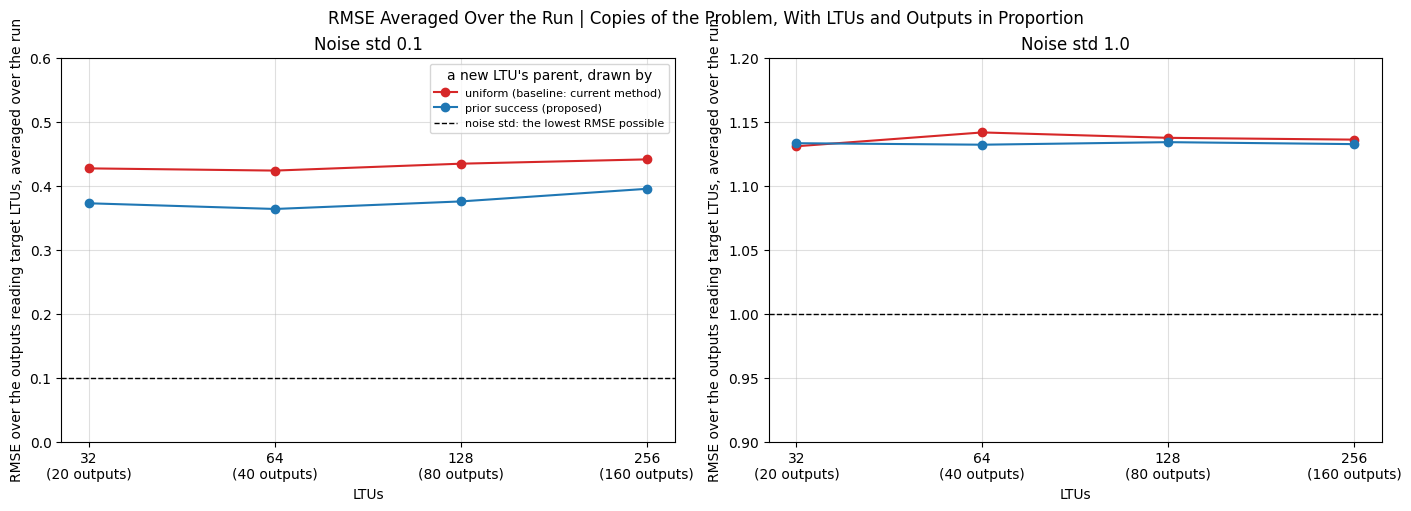

noise std 0.1, 32 LTUs, RMSE averaged over the run: uniform 0.427, prior success 0.373
noise std 0.1, 64 LTUs, RMSE averaged over the run: uniform 0.424, prior success 0.364
noise std 0.1, 128 LTUs, RMSE averaged over the run: uniform 0.435, prior success 0.376
noise std 0.1, 256 LTUs, RMSE averaged over the run: uniform 0.441, prior success 0.395
noise std 1.0, 32 LTUs, RMSE averaged over the run: uniform 1.131, prior success 1.133
noise std 1.0, 64 LTUs, RMSE averaged over the run: uniform 1.142, prior success 1.132
noise std 1.0, 128 LTUs, RMSE averaged over the run: uniform 1.138, prior success 1.134
noise std 1.0, 256 LTUs, RMSE averaged over the run: uniform 1.136, prior success 1.133


In [7]:
LTUS = [LTUS_PER_COPY * copies for copies in COPIES]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for ax, noise, ylim in zip(axes, NOISE_STDS, [(0, 0.6), (0.9, 1.2)]):
    for name, role, rule, color in RULES:
        ax.plot(LTUS, [results[(copies, noise, rule)].mean() for copies in COPIES], 'o-', color=color,
                label=f'{name} ({role})')
    ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
    ax.set(xscale='log', xticks=LTUS, xticklabels=[f'{n}\n({N_OUTPUTS * c} outputs)' for n, c in zip(LTUS, COPIES)],
           xlabel='LTUs', ylabel='RMSE over the outputs reading target LTUs, averaged over the run', ylim=ylim,
           title=f'Noise std {noise}')
    ax.minorticks_off()
    ax.grid(alpha=0.4)
axes[0].legend(title="a new LTU's parent, drawn by", fontsize=8)
fig.suptitle('RMSE Averaged Over the Run | Copies of the Problem, With LTUs and Outputs in Proportion')
plt.show()

for noise in NOISE_STDS:
    for copies in COPIES:
        print(f'noise std {noise}, {LTUS_PER_COPY * copies} LTUs, RMSE averaged over the run: '
              + ', '.join(f'{name} {results[(copies, noise, rule)].mean():.3f}' for name, _, rule, _ in RULES))

## Results

**Prior success keeps its gain.** At noise std 0.1, its RMSE averaged over the run stays 0.05 to 0.06 below uniform
parents' from 32 to 256 LTUs (0.373 against 0.427, and 0.395 against 0.441). The slightly smaller gap at 256 LTUs is
within the spread over seeds: with 32 LTUs, the gap ranges from 0.02 to 0.09 over the 5 seeds. At noise std 1, it
stays level with uniform parents at every size (1.133 against 1.131, and 1.133 against 1.136).

**Why it scales.** Each part of the rule uses the statistics of one output or of one LTU: an output's error, explained
fraction, wins and trials, and the rise in a parent's error when one of its LTUs is removed. The number of LTUs or of
outputs appears nowhere, so only ratios can change the result, such as the number of new LTUs per output, and the
copies keep them. Notebook 2's 100 outputs show the limit of one such ratio: with many more outputs than new LTUs,
most outputs get no trial, and the prior decides.